# Exercise 43 – Gradients of a 2D function

**Week 8 · Automatic differentiation**

Himmelblau's function

$$f(x_1, x_2) = (x_1^2 + x_2 - 11)^2 + (x_1 + x_2^2 - 7)^2$$

has four minima. With `y.backward()` we get the gradient at any point; the
arrows below show the normalised gradient, which points uphill and is
perpendicular to the contour lines.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch


def himmelblau(x1, x2):
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

grad f(-2.0, 1.5) = [ 30.5 -51.5]
grad f(2.0, 0.1) = [-65.18      -15.7960005]
grad f(-3.0, -1.5) = [26.5 39.5]


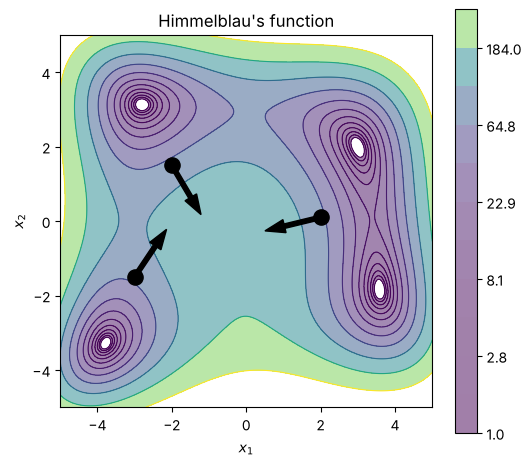

In [2]:
vals = np.linspace(-5, 5, 500)
X1, X2 = np.meshgrid(vals, vals)
levels = np.geomspace(1, 310, 12)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.contour(X1, X2, himmelblau(X1, X2), levels=levels, linewidths=0.8)
filled = ax.contourf(X1, X2, himmelblau(X1, X2), levels=levels, alpha=0.5)
fig.colorbar(filled, ax=ax)

for start in [[-2.0, 1.5], [2.0, 0.1], [-3.0, -1.5]]:
    point = torch.tensor(start, requires_grad=True)
    himmelblau(*point).backward()
    direction = point.grad / point.grad.norm()
    ax.scatter(*start, s=120, c="k", zorder=3)
    ax.arrow(*start, *direction.numpy(), width=0.12, color="k", zorder=3)
    print(f"grad f{tuple(start)} = {point.grad.numpy()}")

ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal", title="Himmelblau's function")
plt.show()